<a href="https://colab.research.google.com/github/HafizRizqi/MachineLearning_2026/blob/main/JS08/JS08_Tugas_Lab_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAMA : HAFIZ RIZQI HERNANDA
# NIM : 244107020154
# KELAS : TI - 3C

#🎗️Tugas Lab 1
- Gunakan dataset CC_Customer_Dataset.csv dari Tugas Lab

- Buatlah model klasterisasi dengan menggunakan Agglomerative Clustering dengan seluruh variabel yang dapat digunakan.

- Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Tunjukkan bentuk cluster-nya berdasarkan dua fitur tersebut.

- Tentukan nilai silhouette score dan DBI dari model.

Langkah 0 - Upload Dataset

In [1]:
from google.colab import files
uploaded = files.upload()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


Langkah 1 - Import Library

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

Langkah 2 - Load dan Membaca Dataset

In [3]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


Cek ukuran dataset :

In [4]:
print("Ukuran Dataset:", df.shape)

Ukuran Dataset: (660, 7)


Cek Informasi Dataset (Missing Values) :

In [5]:
print("\nInformasi Dataset:")
df.info()

print("\nJumlah Missing Value:")
print(df.isnull().sum())


Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Jumlah Missing Value:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


Langkah 3 — Memilih seluruh fitur yang dapat digunakan

In [11]:
features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

missing_cols = [col for col in features if col not in df.columns]
if missing_cols:
    raise ValueError(f'Kolom berikut tidak ditemukan pada dataset: {missing_cols}')

data_model = df.dropna(subset=features).copy()
X = data_model[features]

print('Jumlah data yang digunakan:', len(X))
print('Fitur yang digunakan:', features)
display(X.head())

Jumlah data yang digunakan: 660
Fitur yang digunakan: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


Langkah 4 — Standardisasi fitur

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Bentuk data setelah scaling:', X_scaled.shape)
print(X_scaled[:5])

Bentuk data setelah scaling: (660, 5)
[[ 1.74018685 -1.24922476 -0.86045063 -0.54748969 -1.25153737]
 [ 0.41029254 -0.78758515 -1.47373077  2.5205186   1.89185881]
 [ 0.41029254  1.05897329 -0.86045063  0.13428993  0.1455276 ]
 [-0.12166518  0.13569407 -0.86045063 -0.54748969  0.1455276 ]
 [ 1.74018685  0.59733368 -1.47373077  3.20229822 -0.20373864]]


Langkah 5 — Membandingkan jumlah cluster

Agglomerative Clustering memerlukan jumlah cluster yang ditentukan. Untuk memilih jumlah yang masuk akal, model dicoba pada k 2 sampai 8. Silhouette Score yang lebih tinggi cenderung lebih baik, sedangkan Davies-Bouldin Index (DBI) yang lebih rendah cenderung lebih baik.

In [14]:
hasil_evaluasi = []

for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        metric='euclidean',
        linkage='ward'
    )
    labels = model.fit_predict(X_scaled)

    hasil_evaluasi.append({
        'Jumlah Cluster': k,
        'Silhouette Score': silhouette_score(X_scaled, labels),
        'Davies-Bouldin Index': davies_bouldin_score(X_scaled, labels)
    })

hasil_evaluasi = pd.DataFrame(hasil_evaluasi)
display(hasil_evaluasi.round(4))

,Jumlah Cluster,Silhouette Score,Davies-Bouldin Index
0,2,0.4177,0.9326
1,3,0.5148,0.6810
2,4,0.3481,1.1493
3,5,0.2569,1.3851
4,6,0.2268,1.4109
5,7,0.2163,1.4394
6,8,0.2187,1.4489


Langkah 6 — Membuat model Agglomerative Clustering

Berdasarkan pengujian pada dataset diatas, k = 3 memberikan Silhouette Score tertinggi dan DBI terendah di antara nilai k yang diuji (2–8). Karena itu model akhir menggunakan 3 cluster.

In [15]:
jumlah_cluster = 3

hc = AgglomerativeClustering(
    n_clusters=jumlah_cluster,
    metric='euclidean',
    linkage='ward'
)
y_hc = hc.fit_predict(X_scaled)

data_hasil = data_model.copy()
data_hasil['Cluster'] = y_hc

print('Jumlah cluster terbentuk:', len(np.unique(y_hc)))
print('Jumlah anggota masing-masing cluster:')
print(data_hasil['Cluster'].value_counts().sort_index())

Jumlah cluster terbentuk: 3
Jumlah anggota masing-masing cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64


Langkah 7 — Scatterplot berdasarkan dua variabel yang diminta

Cluster dibentuk menggunakan lima fitur setelah scaling. Scatterplot berikut hanya menampilkan dua fitur, yaitu Avg_Credit_Limit dan Total_Credit_Cards

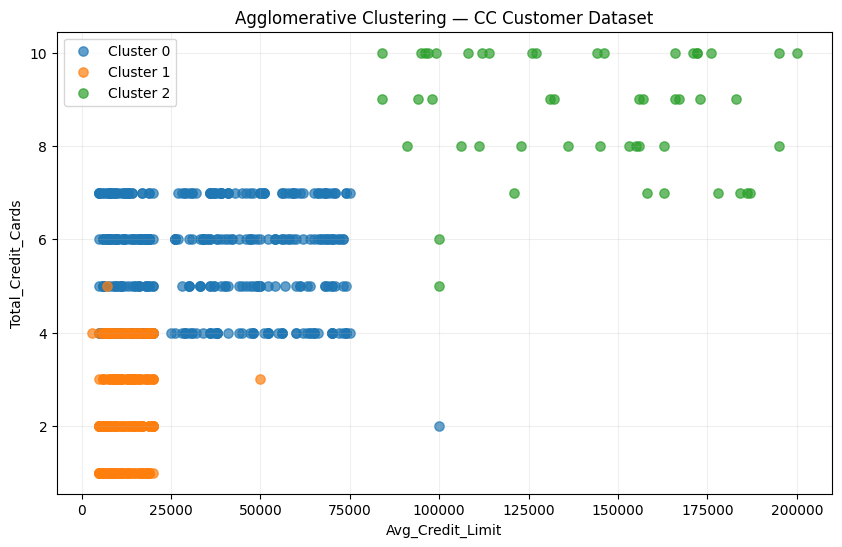

In [16]:
plt.figure(figsize=(10, 6))

for cluster_id in sorted(data_hasil['Cluster'].unique()):
    subset = data_hasil[data_hasil['Cluster'] == cluster_id]
    plt.scatter(
        subset['Avg_Credit_Limit'],
        subset['Total_Credit_Cards'],
        s=45,
        alpha=0.7,
        label=f'Cluster {cluster_id}'
    )

plt.title('Agglomerative Clustering — CC Customer Dataset')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Langkah 8 — Evaluasi model

Silhouette Score menilai seberapa dekat data dengan cluster-nya sendiri dibandingkan cluster lain. DBI membandingkan kekompakan dalam cluster dan jarak antarcluster, nilai yang lebih rendah menunjukkan pemisahan cluster yang lebih baik.

In [17]:
sil_score = silhouette_score(X_scaled, y_hc)
dbi_score = davies_bouldin_score(X_scaled, y_hc)

print(f'Silhouette Score: {sil_score:.4f}')
print(f'Davies-Bouldin Index: {dbi_score:.4f}')

Silhouette Score: 0.5148
Davies-Bouldin Index: 0.6810


Langkah 9 — Karakteristik setiap cluster

In [19]:
ringkasan_cluster = data_hasil.groupby('Cluster')[features].mean().round(2)
jumlah_anggota = data_hasil['Cluster'].value_counts().sort_index().rename('Jumlah Anggota')
ringkasan_cluster = jumlah_anggota.to_frame().join(ringkasan_cluster)
display(ringkasan_cluster)

,Jumlah Anggota,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,,
0,385,33851.95,5.52,3.49,0.98,1.99
1,225,12151.11,2.42,0.94,3.55,6.86
2,50,141040.00,8.74,0.60,10.90,1.08


# Kesimpulan
Agglomerative Clustering berhasil membagi data pelanggan menjadi tiga kelompok. Nilai evaluasi menunjukkan pemisahan cluster yang cukup terlihat, tetapi tidak berarti semua anggota dalam satu cluster memiliki karakteristik yang identik.